# **Теория №2. Применение метода «скользящего окна» для поиска объектов на изображении по эталонам в среде Python. Нелинейные фильтры**


## **Фильтрация изображений**

- Фильтрация изображений — популярный инструмент, используемый
при обработке изображений. Мы используем фильтрацию
изображений, чтобы удалить шум и любые нежелательные артефакты из
изображения, создавая улучшенную версию этого изображения.

- Существуют два типа фильтров: линейный (рассматривали на предыдущем занятии) и нелинейный. Примерами линейных фильтров являются средние, лапласовские и прочие фильтры с изначально заданными параметрами ядра. Нелинейные
фильтры представляют собой фильтры, такие как медиана, минимум,
максимум и фильтры Собеля.

- Каждый из этих фильтров имеет определенное назначение и
предназначен для удаления шума или улучшения некоторых аспектов
изображения.

## **Как мы выполняем фильтрацию изображения? (Повторение)**

- Чтобы выполнить процесс фильтрации изображений, нам нужен фильтр,
также называемый маской. Этот фильтр обычно представляет собой
двумерное квадратное окно, то есть окно с равными размерами (шириной и
высотой).

- Фильтр будет включать числа. Эти числа называются коэффициентами,
и именно они фактически определяют эффект фильтра и то, как будет
выглядеть выходное изображение. На рисунке ниже показан пример фильтра
3x3, имеющего девять значений (коэффициентов).

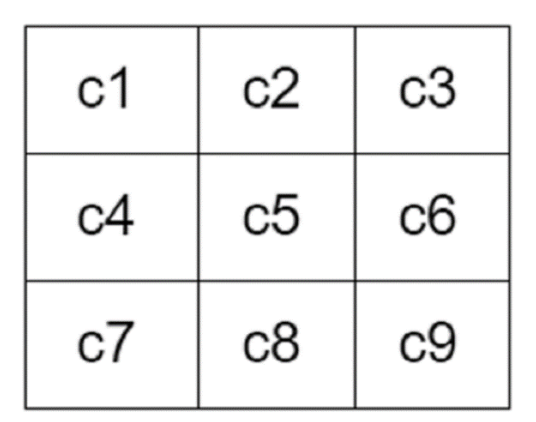

- Чтобы применить фильтр, окно 3x3 «скользит» по изображению. Этот
процесс «скольжения» окна фильтра по изображению называется сверткой в
пространственной области. Окно будет размещено на каждом пикселе (т.е.
будет «думать» о нем как о ячейке в матрице) на изображении, где центр
фильтра должен перекрывать этот пиксель.

- Как только это перекрытие произойдет, пиксели в подизображении, над
которым находится фильтр, будут умножены на соответствующие
коэффициенты фильтра. В этом случае у нас будет новая матрица с новыми
значениями, похожими на размер фильтра (т.е. 3x3). Наконец, значение
центрального пикселя будет заменено новым значением с использованием
конкретного математического уравнения в зависимости от типа
используемого фильтра (то есть медианного фильтра).

- Рассмотрим пример того, как фильтр изображений применяется в
действии. Предположим, у нас есть следующее подизображение, где наш
фильтр перекрывается (i и j относятся к расположению пикселя в
подизображении, а I относится к изображению):

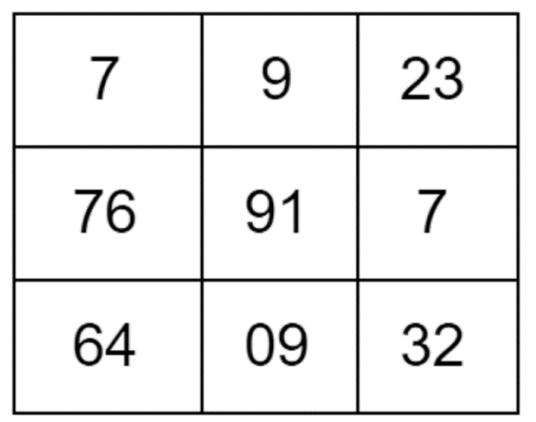

Свертка нашего фильтра, показанного на первом рисунке с
изображением выше, будет выглядеть, как показано ниже, где I_new(i,j)
представляет результат в местоположении (i,j) .

I_new(i,j) = v1 x I(i-1,j-1) + v2 x I(i-1,j) + v3 x I(i-1,j+1) + v4 x I(i,j-1) + v5
x I(i,j) + v6 x I(i,j+1) + v7 x I(i+1,j-1) + v8 x I(i+1,j) + v9 x I(i+1,j+1)

## **Медианный фильтр**

- В медианном фильтре мы выбираем скользящее окно, которое будет
перемещаться по всем пикселям изображения. Здесь мы собираем значения
пикселов, которые попадают под фильтр, и принимаем медиану этих
значений. Результат будет присвоен центральному пикселю.

- Скажем, наш фильтр 3x3 имел следующие значения после размещения
его на фрагмент изображения:

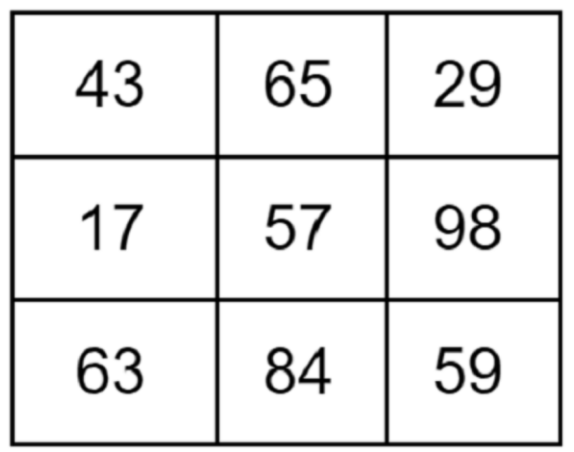

- Посмотрим, как рассчитать медиану. Медиана, по своей сути, является
средним числом отсортированного списка чисел. Таким образом, чтобы найти
медиану для указанного выше фильтра, мы просто сортируем числа по
убыванию, и середина этих чисел будет нашим медианным значением.
Сортировка значений в нашем окне 3x3 даст нам следующее:

    17 29 43 57 59 63 65 84 98

- Чтобы найти среднее число (медиану), мы просто посчитаем количество
имеющихся у нас значений, добавим 1 к этому числу и разделим на 2. Это даст
нам местоположение среднего значения в окне, которое является нашим
медианным значением. Таким образом, медиана будет в местоположении
9+1/2 = 5, что составляет 59. Это значение будет новым значением пикселя под
центром нашего окна 3x3.

- Этот тип фильтра используется для удаления шума. На изображении
ниже показан пример изображения, страдающего от такого шума (до и после
применения медианного фильтра):

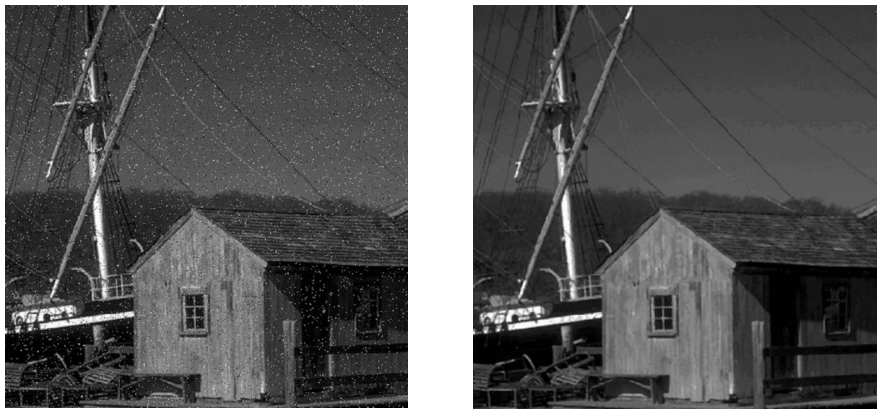

**Практический пример применения медианного фильтра:**

Исходное изображение:


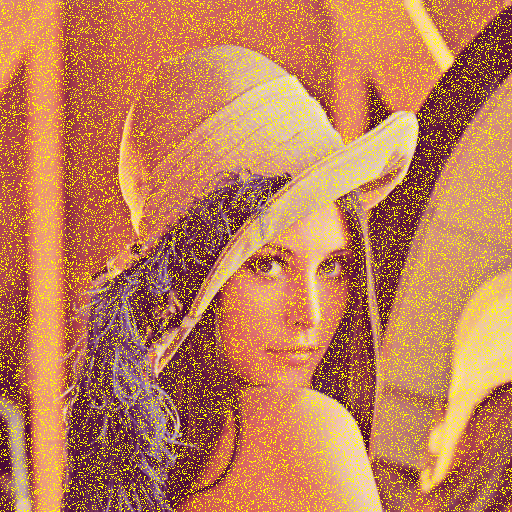

Обработанное изображение:


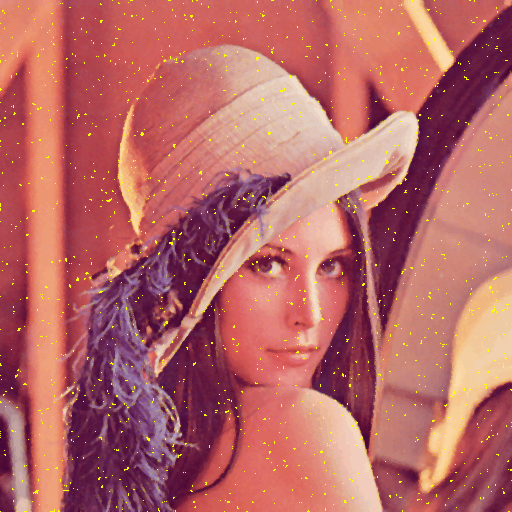

In [ ]:
# Импортируем необходимые библиотеки
import cv2
from google.colab.patches import cv2_imshow

# Указываем путь изображению
image_path = 'image.png'  # Убедитесь, что изображение загружено в файловую систему Colab

# Загружаем изображение
image = cv2.imread(image_path)

# Проверяем, что изображение загрузилось корректно
if image is None:
    print("Ошибка: изображение не найдено по указанному пути.")
else:
    # Применяем медианный фильтр 3×3 к изображению
    processed_image = cv2.medianBlur(image, 3)

    # Отображаем исходное изображение
    print("Исходное изображение:")
    cv2_imshow(image)

    # Отображаем обработанное изображение
    print("Обработанное изображение:")
    cv2_imshow(processed_image)

    # Сохраняем обработанное изображение в текущую директорию
    cv2.imwrite('processed_image.png', processed_image)


- Чтобы применить медианный фильтр, мы просто используем
cv2.medianBlur(). После передачи нашего изображения в качестве аргумента
командной строки, мы читаем это изображение с помощью функции
cv2.imread(). Затем мы применяем медианный фильтр, используя medianBlur()
, передавая наше изображение и размер фильтра в качестве параметров.
Изображение отображается с помощью функции cv2.imshow() и сохраняется
на диск с помощью cv2.imwrite().

## **Средний фильтр**

- Средний фильтр является примером линейного фильтра. Он в основном
заменяет каждый пиксель в выходном изображении на среднее (среднее)
значение окрестности. Это приводит к сглаживанию изображения
(уменьшению количества вариаций интенсивности между пикселем и
следующим), удалению шума с изображения и повышению яркости
изображения.

- Таким образом, при средней фильтрации каждый пиксель изображения
будет заменен средним значением его соседей, включая сам пиксель. Ядро 3x3
используемое для средней фильтрации, показано на рисунке ниже, хотя можно
использовать и другие размеры ядра (например, 5×5):

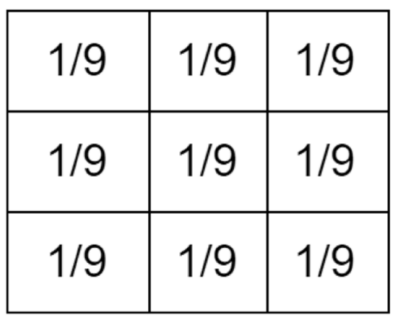

- То, что вышеописанное ядро на самом деле пытается нам сказать, это
то, что мы суммируем все элементы под ядром и берем среднее (среднее) от
суммы.

- Давайте рассмотрим пример, чтобы прояснить ситуацию. Скажем, у
нас есть следующее изображение:

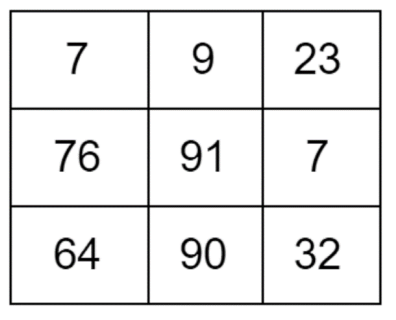

- При применении фильтра средних значений мы будем делать
следующее:

    (7+9+23+76+91+7+64+90+32)/9 = 44

- Точный результат — 44.3, но можно округлить его до 44 . Таким
образом, новое значение для центрального пикселя становится равным 44
вместо 91.

Изображение до и после применения к нему фильтра средних частот:

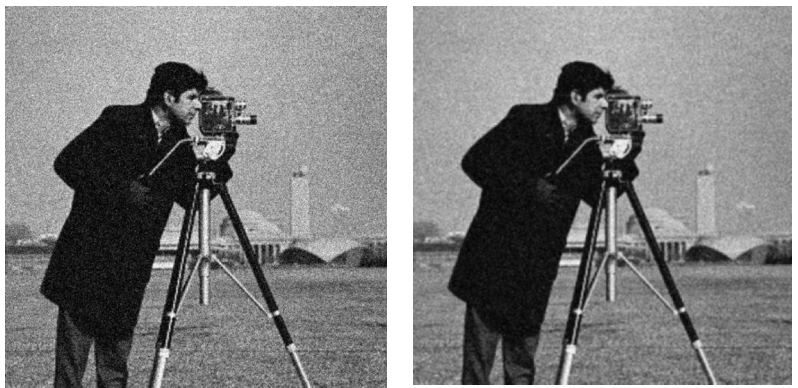

**Практический пример применения фильтра стредних частот:**

Исходное изображение:


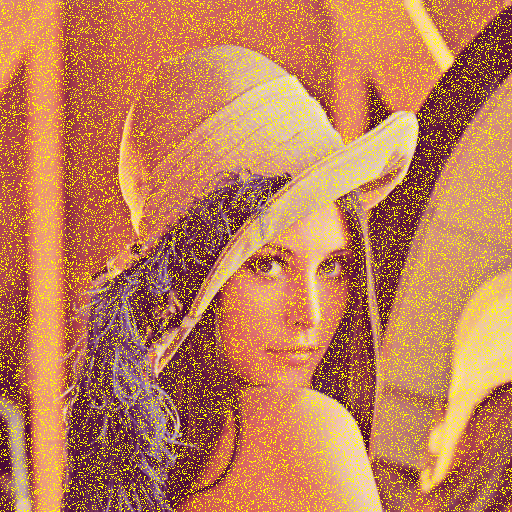

Обработанное изображение:


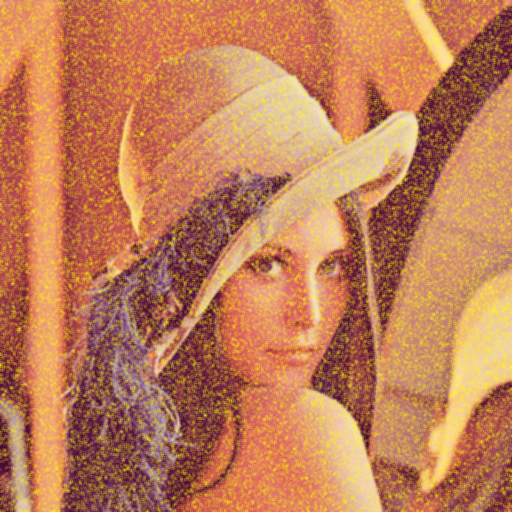

In [ ]:
# Импортируем необходимые библиотеки
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

# Указываем путь к изображению
image_path = 'image.png'  # Убедитесь, что изображение загружено в файловую систему Colab

# Загружаем изображение
image = cv2.imread(image_path)

# Проверяем, что изображение загрузилось корректно
if image is None:
    print("Ошибка: изображение не найдено по указанному пути.")
else:
    # Применяем фильтр средних частот 3x3 к изображению
    kernel = np.ones((3, 3), np.float32) / 9
    processed_image = cv2.filter2D(image, -1, kernel)

    # Отображаем исходное изображение
    print("Исходное изображение:")
    cv2_imshow(image)

    # Отображаем обработанное изображение
    print("Обработанное изображение:")
    cv2_imshow(processed_image)

    # Сохраняем обработанное изображение в текущую директорию
    cv2.imwrite('processed_image.png', processed_image)


- Обратите внимание, что мы использовали ядро 3x3 для нашего среднего
фильтра. Мы также использовали метод filter2D() для применения среднего фильтра.

- Первый параметр этой функции — наше входное изображение, второй —
желаемая глубина ddepth выходного изображения, а третий параметр — наше
ядро. Присвоение -1 для параметра ddepth означает, что выходное
изображение будет иметь ту же глубину, что и входное изображение.

## **Поиск объектов на изображении по эталонам**

Для решения данной задачи нам необходимы два изображения для
выполнения сопоставления с шаблоном.

- Первое изображение – это весь растр полностью.

- Второе изображение –
фрагмент на растре, который необходимо найти.

Алгоритм выполнения поиска:

Исходное изображение с выделенным фраментом:


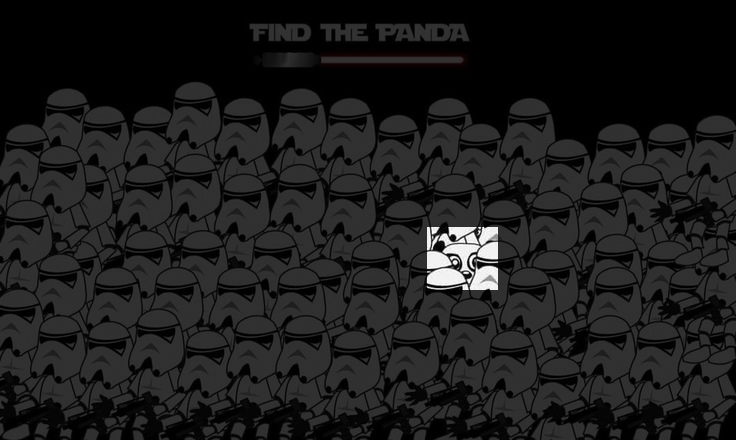

Фрамент изображения (эталон):


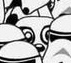

In [ ]:
import numpy as np
import cv2
from google.colab.patches import cv2_imshow

# Загружаем исходное изображение
image = cv2.imread('/content/panda.jpg')

# Загружаем фрамент изображения (эталон)
fragment = cv2.imread('/content/panda_fragment.jpg')

# Проверяем, что изображения успешно загружены
if image is None:
    print("Ошибка: не удалось загрузить исходное изображение.")
if fragment is None:
    print("Ошибка: не удалось загрузить фрамент изображения.")

# Получаем размеры фрамента
(fragmentHeight, fragmentWidth) = fragment.shape[:2]

# Осуществляем поиск фрамента на изображении
result = cv2.matchTemplate(image, fragment, cv2.TM_CCOEFF)
(_, _, minLoc, maxLoc) = cv2.minMaxLoc(result)

# Выделяем искомый фрамент и отделяем его от изображения
topLeft = maxLoc
botRight = (topLeft[0] + fragmentWidth, topLeft[1] + fragmentHeight)
roi = image[topLeft[1]:botRight[1], topLeft[0]:botRight[0]].copy()

# Создаем затемненный прозрачный слой для затемнения всего изображения
mask = np.zeros(image.shape, dtype="uint8")
image_dark = cv2.addWeighted(image, 0.2, mask, 0.75, 0)

# Возвращаем искомый фрамент в изображение
image_dark[topLeft[1]:botRight[1], topLeft[0]:botRight[0]] = roi

# Масштабируем изображение для отображения, если необходимо
max_height = 950
if image_dark.shape[0] > max_height:
    scale = max_height / image_dark.shape[0]
    image_display = cv2.resize(image_dark, None, fx=scale, fy=scale)
else:
    image_display = image_dark

# Отображаем результаты
print("Исходное изображение с выделенным фраментом:")
cv2_imshow(image_display)

print("Фрамент изображения (эталон):")
cv2_imshow(fragment)


Проверка на соответствие с шаблоном реализуется с помощью функции
cv2.matchTemplate, которая требует трех параметров:

- Первый параметр - это
весь растр полностью.
- Второй параметр – фрагмент на растре, который
необходимо найти.
- Наконец, третий аргумент - это метод сопоставления с
8
шаблоном.

Существует множество методов для сопоставления с шаблоном, но
в данном случае мы используем коэффициент корреляции, который
определяется параметром cv2.TM_CCOEFF.

**Что именно делает функция cv2.matchTemplate?**

- По сути, эта функция реализует метод «скользящего окна», а именно
«перемещает» фрагмент по цельному растру слева направо и сверху вниз, по
одному пикселю за раз. Затем для каждого из этих местоположений вычисляет
коэффициент корреляции, чтобы определить уровень совпадения
(высокий/низкий).

- Регионы с достаточно высокой корреляцией можно считать «хорошими»
совпадениями для нашего шаблона.

- Далее вызывается метод cv2.minMaxLoc
для нахождения области с наибольшим значением коэффициента корреляции.

- Остальная часть кода программы включает в себя извлечение области, в
которой находится объект, и затем выделение его в исходном изображении.